# Machine Learning — Dubai DLD Sales

Notebook này áp dụng 2 hướng Machine Learning trên dữ liệu đã làm sạch trong MySQL `dld`:

1. **Mô hình định giá (hồi quy):** dự đoán giá/sqft hợp lý của một căn nhà ở từ vị trí, loại BĐS, diện tích, số phòng… → trả lời *"căn này giá bao nhiêu là hợp lý?"*
2. **Phân cụm khu vực (K-Means):** gom các khu vực có hành vi giá giống nhau → trả lời *"nên chú ý nhóm khu vực nào?"*

**Phạm vi dữ liệu:** chỉ nhà ở (`property_type in (Unit, Villa)` và `usage = Residential`), giống measure *Median PSF Residential* trong Power BI, vì đất và cả tòa nhà định giá theo logic khác.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_absolute_error, silhouette_score
from sklearn.cluster import KMeans

from utils.config import DB_CONFIG
from utils.db import make_engine, load_main_dataset

BLUES = ["#1F5FAD", "#5DA9E9", "#0B2A55", "#9CC8F0", "#2E86C1", "#7FA7D6"]
sns.set_theme(style="whitegrid", palette=BLUES)
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", "{:,.2f}".format)

## 0. Đọc dữ liệu từ MySQL

In [2]:
engine = make_engine(DB_CONFIG)
query = '''
SELECT f.price_psf, f.area_sqm, d.full_date, d.year, d.month,
       a.area_id, a.area_name_en, pj.master_project_name,
       p.property_type_label, p.property_sub_type, p.rooms_label, p.parking_label,
       pc.reg_type_label
FROM fact_sales f
JOIN dim_date d      USING (date_id)
JOIN dim_area a      USING (area_id)
JOIN dim_project pj  USING (project_id)
JOIN dim_property p  USING (property_id)
JOIN dim_procedure pc USING (procedure_id)
WHERE p.property_type_label IN ('Unit', 'Villa')
  AND p.usage_label = 'Residential'
'''
df = load_main_dataset(query, engine)
df["price_psf"] = df["price_psf"].astype(float)
df["area_sqm"] = df["area_sqm"].astype(float)
print(f"{len(df):,} giao dịch nhà ở, {df['year'].min()}–{df['year'].max()}")
df.head()

1,082,036 giao dịch nhà ở, 2004–2026


,price_psf,area_sqm,full_date,year,month,area_id,area_name_en,master_project_name,property_type_label,property_sub_type,rooms_label,parking_label,reg_type_label
0,"2,923.21",50.91,2009-09-28,2009,9,330,Marsa Dubai,Dubai Marina,Unit,Flat,Studio,No,Off-Plan
1,880.25,47.19,2009-08-05,2009,8,485,Me'Aisem First,International Media Production Zone,Unit,Flat,Studio,No,Off-Plan
2,895.35,47.19,2009-08-05,2009,8,485,Me'Aisem First,International Media Production Zone,Unit,Flat,Studio,No,Off-Plan
3,"1,045.38",47.19,2009-04-14,2009,4,485,Me'Aisem First,International Media Production Zone,Unit,Flat,Studio,No,Off-Plan
4,895.35,47.19,2009-08-05,2009,8,485,Me'Aisem First,International Media Production Zone,Unit,Flat,Studio,No,Off-Plan


---
# Phần 1 — Mô hình định giá (hồi quy)

## 1.1 Biến mục tiêu: `log(price_psf)`
Giá/sqft lệch phải mạnh (có căn rất đắt), nên mô hình học trên **log** để phân phối gần chuẩn hơn và sai số được tính theo **tỷ lệ %** thay vì số tuyệt đối.

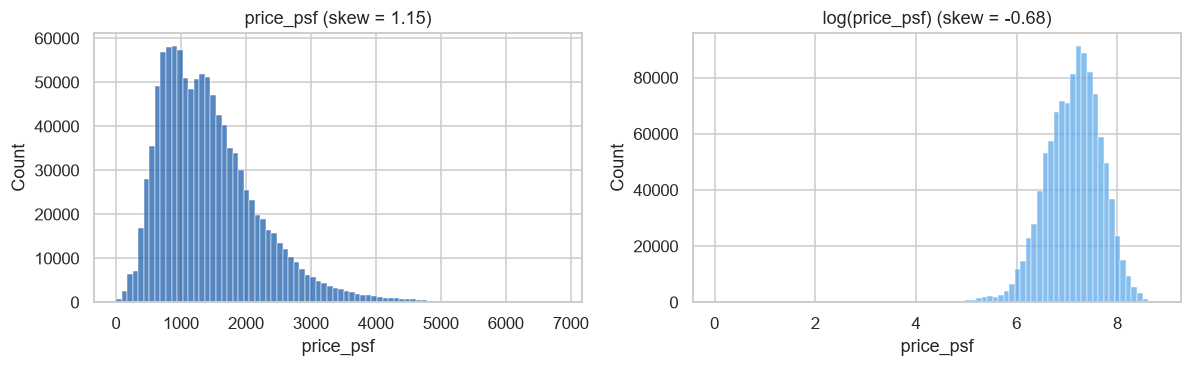

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(df["price_psf"], bins=80, ax=ax[0], color=BLUES[0])
ax[0].set_title(f"price_psf (skew = {df['price_psf'].skew():.2f})")
sns.histplot(np.log(df["price_psf"]), bins=80, ax=ax[1], color=BLUES[1])
ax[1].set_title(f"log(price_psf) (skew = {np.log(df['price_psf']).skew():.2f})")
plt.tight_layout(); plt.show()

## 1.2 Biến đầu vào và chống rò rỉ dữ liệu (data leakage)

| Nhóm | Biến |
|---|---|
| Vị trí | `area_name_en`, `master_project_name` |
| Sản phẩm | `property_type_label`, `property_sub_type`, `rooms_label`, `parking_label`, `log(area_sqm)` |
| Loại giao dịch | `reg_type_label` (Off-Plan / Ready) |
| Thời điểm | `month`, **`market_psf_lag1`** |

- **Không dùng `price_aed`**: `price_psf = price_aed / sqft`, đưa giá vào là mô hình "nhìn trộm đáp án".
- **`market_psf_lag1`** = median giá/sqft toàn thị trường của **tháng trước**. Đây là thông tin đã biết *trước* khi giao dịch xảy ra, giúp mô hình theo kịp xu hướng thị trường. Mô hình dạng cây không tự ngoại suy được năm mới (2025 cao hơn mọi năm trong tập train), nên cần biến này.
- Chỉ dùng dữ liệu từ 2012 (giai đoạn sau khủng hoảng 2008–2011).

In [4]:
df["ym"] = pd.to_datetime(df["full_date"]).dt.to_period("M")
market = df.groupby("ym")["price_psf"].median()
df["market_psf_lag1"] = df["ym"].map(market.shift(1))

data = df[df["year"] >= 2012].dropna(subset=["market_psf_lag1"]).copy()
data["log_psf"] = np.log(data["price_psf"])
data["log_area"] = np.log(data["area_sqm"])
data["log_mkt"] = np.log(data["market_psf_lag1"])

CATS = ["area_name_en", "master_project_name", "property_type_label", "property_sub_type",
        "rooms_label", "parking_label", "reg_type_label"]
NUMS = ["log_area", "log_mkt", "month"]
FEATURES = CATS + NUMS
for c in CATS:
    data[c] = data[c].astype("category")

## 1.3 Chia train/test theo thời gian
Chia **ngẫu nhiên** sẽ cho kết quả đẹp ảo (mô hình đã thấy giao dịch cùng tháng, cùng tòa nhà). Thực tế định giá là dự đoán **tương lai**, nên: **train = 2012–2024, test = 2025** (năm trọn vẹn gần nhất). Năm 2026 (đến 5/10) dùng làm kiểm tra thêm.

In [5]:
train = data[data["year"] <= 2024]
test = data[data["year"] == 2025]
test26 = data[data["year"] == 2026]
print(f"train: {len(train):,} | test 2025: {len(test):,} | test 2026 YTD: {len(test26):,}")

def evaluate(name, part, pred_log):
    actual = part["price_psf"]
    pred = np.exp(pred_log)
    ape = np.abs(pred - actual) / actual
    return {"model": name, "R2 (log)": r2_score(part["log_psf"], pred_log),
            "MAE (AED/sqft)": mean_absolute_error(actual, pred),
            "MAPE %": ape.mean() * 100, "Median APE %": ape.median() * 100,
            "Within 10% (share)": (ape <= 0.10).mean() * 100}

train: 673,018 | test 2025: 178,962 | test 2026 YTD: 104,648


## 1.4 Huấn luyện 3 mô hình
1. **Naive** — đoán mọi căn bằng median thị trường tháng trước (mốc tối thiểu phải vượt qua).
2. **Ridge regression** — hồi quy tuyến tính có regularization, biến phân loại được one-hot.
3. **LightGBM** — gradient boosting trên cây quyết định, xử lý trực tiếp biến phân loại nhiều giá trị (khoảng 200 khu vực) và quan hệ phi tuyến.

In [6]:
results = [evaluate("Naive (market median)", test, test["log_mkt"])]

ridge = make_pipeline(
    ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50), CATS),
                       ("num", StandardScaler(), NUMS)]),
    Ridge(alpha=1.0))
ridge.fit(train[FEATURES], train["log_psf"])
results.append(evaluate("Ridge", test, ridge.predict(test[FEATURES])))

lgbm = lgb.LGBMRegressor(n_estimators=800, learning_rate=0.05, num_leaves=127, min_child_samples=50,
                         subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                         random_state=42, verbose=-1)
lgbm.fit(train[FEATURES], train["log_psf"], categorical_feature=CATS)
test_pred = lgbm.predict(test[FEATURES])
results.append(evaluate("LightGBM", test, test_pred))
results.append(evaluate("LightGBM (2026 YTD)", test26, lgbm.predict(test26[FEATURES])))

scores = pd.DataFrame(results).set_index("model")
scores

,R2 (log),MAE (AED/sqft),MAPE %,Median APE %,Within 10% (share)
model,,,,,
Naive (market median),-0.00,558.73,32.19,24.98,20.40
Ridge,0.44,358.26,18.55,15.12,34.10
LightGBM,0.64,316.79,15.97,13.41,37.45
LightGBM (2026 YTD),0.33,425.68,23.99,16.56,32.54


## 1.5 Mô hình dự đoán tốt đến đâu?

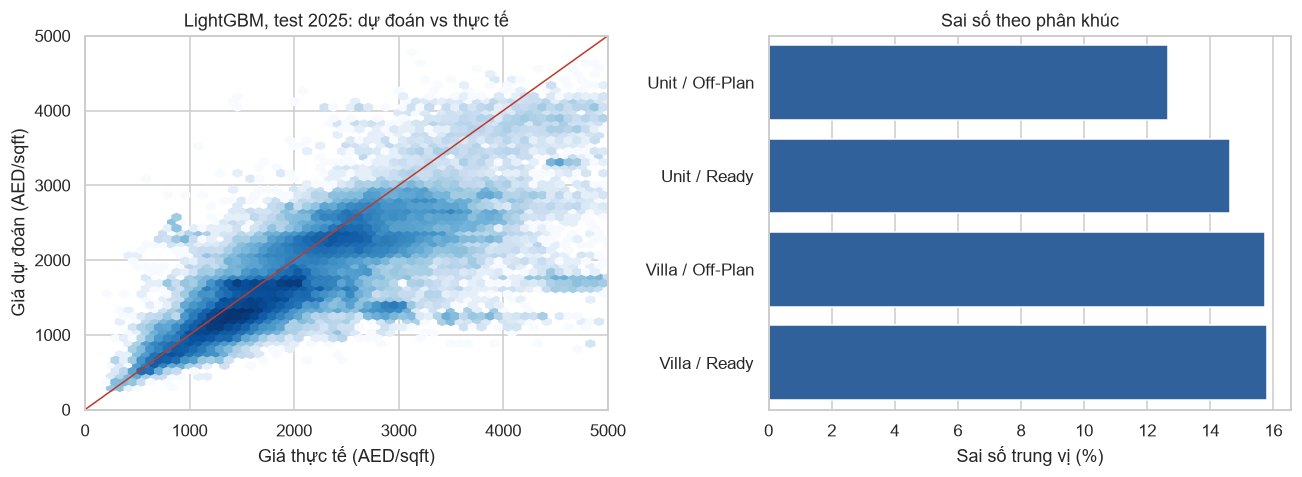

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].hexbin(test["price_psf"], np.exp(test_pred), gridsize=60, bins="log", cmap="Blues",
             extent=(0, 5000, 0, 5000))
ax[0].plot([0, 5000], [0, 5000], color="#C0392B", lw=1)
ax[0].set(xlim=(0, 5000), ylim=(0, 5000), xlabel="Giá thực tế (AED/sqft)", ylabel="Giá dự đoán (AED/sqft)",
          title="LightGBM, test 2025: dự đoán vs thực tế")

ape = (np.abs(np.exp(test_pred) - test["price_psf"]) / test["price_psf"] * 100).rename("APE")
seg = pd.concat([test[["reg_type_label", "property_type_label"]].astype(str), ape], axis=1)
seg["segment"] = seg["property_type_label"] + " / " + seg["reg_type_label"]
order = seg.groupby("segment")["APE"].median().sort_values().index
sns.barplot(data=seg, y="segment", x="APE", estimator=np.median, errorbar=None, order=order,
            ax=ax[1], color=BLUES[0])
ax[1].set(xlabel="Sai số trung vị (%)", ylabel="", title="Sai số theo phân khúc")
plt.tight_layout(); plt.show()

## 1.6 Yếu tố nào quyết định giá?

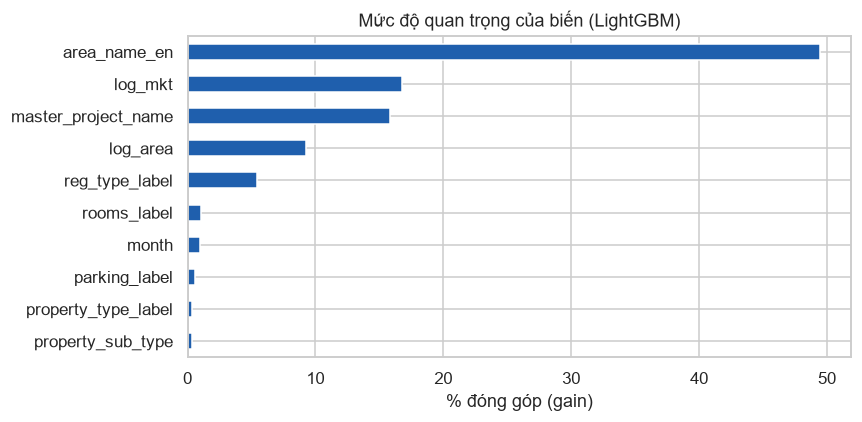

area_name_en          49.40
log_mkt               16.70
master_project_name   15.80
log_area               9.30
reg_type_label         5.40
rooms_label            1.00
month                  1.00
parking_label          0.60
property_type_label    0.40
property_sub_type      0.30
dtype: float64

In [8]:
importance = pd.Series(lgbm.booster_.feature_importance("gain"), index=FEATURES)
importance = (importance / importance.sum() * 100).sort_values()
ax = importance.plot.barh(figsize=(8, 4), color=BLUES[0])
ax.set(xlabel="% đóng góp (gain)", title="Mức độ quan trọng của biến (LightGBM)")
plt.tight_layout(); plt.show()
importance.sort_values(ascending=False).round(1)

## 1.7 Thử nghiệm: thêm tên dự án và tòa nhà có tốt hơn không?
Trực giác: biết cụ thể căn nằm ở tòa nào thì đoán giá chuẩn hơn. Thử thêm `project_name` và `building_name` (hàng nghìn giá trị).

In [9]:
q2 = query.replace("pj.master_project_name,", "pj.master_project_name, pj.project_name, pj.building_name,")
d2 = load_main_dataset(q2, engine)
d2["price_psf"] = d2["price_psf"].astype(float); d2["area_sqm"] = d2["area_sqm"].astype(float)
d2["ym"] = pd.to_datetime(d2["full_date"]).dt.to_period("M")
d2["market_psf_lag1"] = d2["ym"].map(market.shift(1))
d2 = d2[d2["year"] >= 2012].dropna(subset=["market_psf_lag1"]).copy()
d2["log_psf"], d2["log_area"], d2["log_mkt"] = np.log(d2["price_psf"]), np.log(d2["area_sqm"]), np.log(d2["market_psf_lag1"])
CATS2 = CATS + ["project_name", "building_name"]
for c in CATS2:
    d2[c] = d2[c].astype("category")
tr2, te2 = d2[d2["year"] <= 2024], d2[d2["year"] == 2025]
m2 = lgb.LGBMRegressor(**lgbm.get_params()).fit(tr2[CATS2 + NUMS], tr2["log_psf"], categorical_feature=CATS2)
new_projects = ~te2["project_name"].isin(set(tr2["project_name"]))
print(f"Giao dịch 2025 thuộc dự án chưa từng xuất hiện trong train: {new_projects.mean():.1%}")
pd.DataFrame([scores.loc["LightGBM"].rename("LightGBM (bộ biến chính)"),
              pd.Series(evaluate("x", te2, m2.predict(te2[CATS2 + NUMS]))).drop("model")
                .rename("LightGBM + project/building")])

Giao dịch 2025 thuộc dự án chưa từng xuất hiện trong train: 43.0%


,R2 (log),MAE (AED/sqft),MAPE %,Median APE %,Within 10% (share)
LightGBM (bộ biến chính),0.64,316.79,15.97,13.41,37.45
LightGBM + project/building,0.55,350.50,17.01,14.10,36.78


## 1.8 Ứng dụng: khu vực nào đang giao dịch cao/thấp hơn giá mô hình?
Với mỗi khu vực, so **giá thực tế** với **giá mô hình dự đoán** cho cùng loại căn (năm 2025). Chênh lệch dương nghĩa là người mua đang trả cao hơn mức mà vị trí, diện tích và loại căn giải thích được, có thể do thương hiệu, view hoặc kỳ vọng tăng giá.

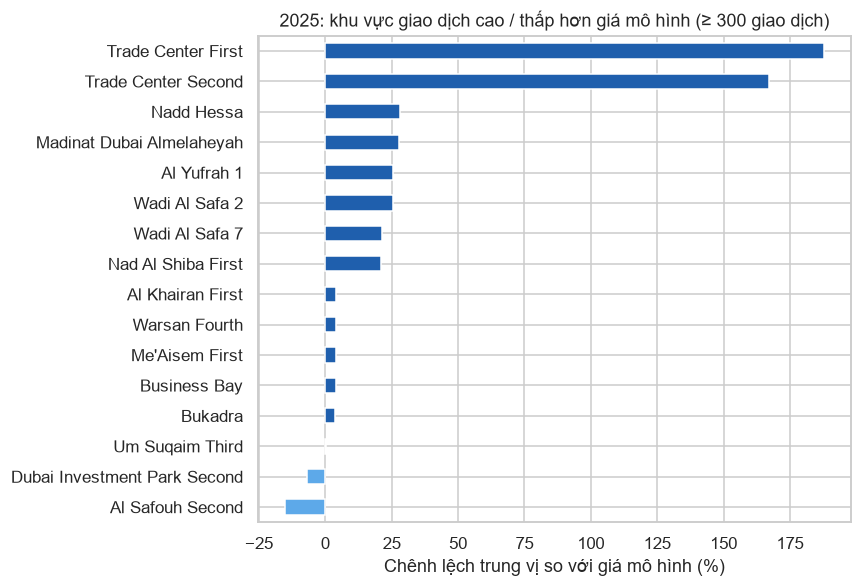

In [10]:
gap = test[["area_name_en", "price_psf"]].copy()
gap["area_name_en"] = gap["area_name_en"].astype(str)
gap["ratio"] = gap["price_psf"] / np.exp(test_pred)
area_gap = gap.groupby("area_name_en").agg(transactions=("ratio", "size"), premium=("ratio", "median"))
area_gap = area_gap[area_gap["transactions"] >= 300]
area_gap["premium_%"] = (area_gap["premium"] - 1) * 100
show = pd.concat([area_gap.nlargest(8, "premium_%"), area_gap.nsmallest(8, "premium_%")])
ax = show["premium_%"].sort_values().plot.barh(figsize=(8, 5.5),
        color=[BLUES[0] if v > 0 else BLUES[1] for v in show["premium_%"].sort_values()])
ax.set(xlabel="Chênh lệch trung vị so với giá mô hình (%)", ylabel="",
       title="2025: khu vực giao dịch cao / thấp hơn giá mô hình (≥ 300 giao dịch)")
plt.tight_layout(); plt.show()

---
# Phần 2 — Phân cụm khu vực (K-Means)

## 2.1 Đặc trưng của từng khu vực
Mỗi khu vực được mô tả bằng 5 chỉ số. Chỉ giữ các khu có **≥ 100 giao dịch nhà ở trong cả năm 2022 và 2025**, để tốc độ tăng giá đáng tin cậy.

| Đặc trưng | Ý nghĩa |
|---|---|
| `psf_2025` | Mức giá: median giá/sqft năm 2025 |
| `growth_22_25` | Tốc độ tăng giá/sqft từ 2022 đến 2025 |
| `transactions_24_25` | Độ sôi động: số giao dịch 2024–2025 (lấy log) |
| `offplan_share` | Tỷ lệ Off-Plan 2024–2025, đại diện cho mức độ khu đang được phát triển |
| `median_size` | Diện tích căn điển hình (lấy log), phân biệt khu căn hộ nhỏ với khu villa |

In [11]:
by_year = data.assign(area_name_en=data["area_name_en"].astype(str)) \
              .groupby(["area_name_en", "year"])["price_psf"].agg(["median", "size"]).unstack()
recent = data[data["year"] >= 2024].assign(area_name_en=lambda d: d["area_name_en"].astype(str))
areas = pd.DataFrame({
    "psf_2025": by_year["median"][2025],
    "growth_22_25": by_year["median"][2025] / by_year["median"][2022] - 1,
    "transactions_24_25": by_year["size"][2024] + by_year["size"][2025],
    "min_yearly_n": by_year["size"][[2022, 2025]].min(axis=1),
})
areas["offplan_share"] = recent.groupby("area_name_en")["reg_type_label"].apply(lambda s: (s == "Off-Plan").mean())
areas["median_size"] = recent.groupby("area_name_en")["area_sqm"].median()
areas = areas[areas["min_yearly_n"] >= 100].dropna().drop(columns="min_yearly_n")
print(f"{len(areas)} khu vực đủ điều kiện")

X = areas.copy()
X["transactions_24_25"] = np.log(X["transactions_24_25"])
X["median_size"] = np.log(X["median_size"])
X_scaled = StandardScaler().fit_transform(X)

49 khu vực đủ điều kiện


## 2.2 Chọn số cụm k
K-Means cần chuẩn hóa dữ liệu trước (`StandardScaler`), nếu không biến có đơn vị lớn (giá/sqft) sẽ lấn át các biến khác. Số cụm được chọn bằng **Elbow** (inertia giảm chậm lại) và **Silhouette** (càng cao, cụm càng tách biệt).

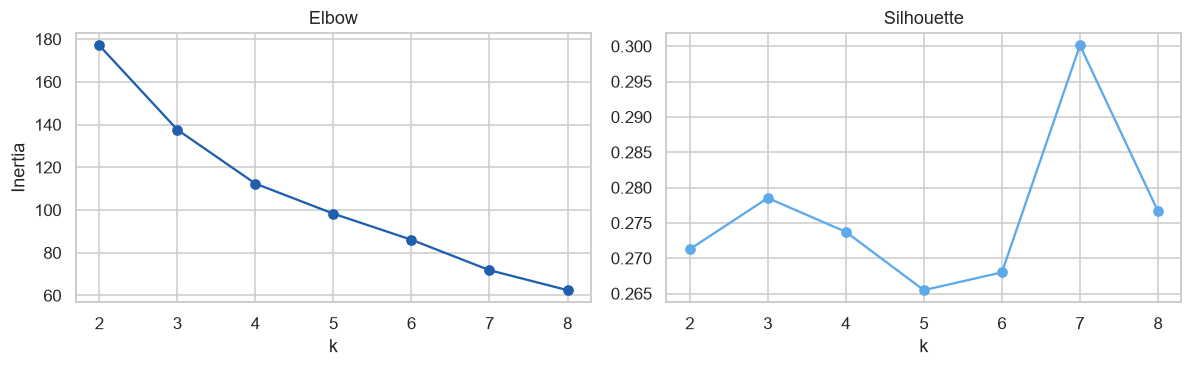

k,2,3,4,5,6,7,8
inertia,177.07,137.60,112.36,98.29,86.07,71.82,62.48
silhouette,0.27,0.28,0.27,0.27,0.27,0.30,0.28


In [12]:
ks = range(2, 9)
fits = {k: KMeans(n_clusters=k, n_init=20, random_state=42).fit(X_scaled) for k in ks}
inertia = [fits[k].inertia_ for k in ks]
silhouette = [silhouette_score(X_scaled, fits[k].labels_) for k in ks]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(list(ks), inertia, marker="o", color=BLUES[0]); ax[0].set(title="Elbow", xlabel="k", ylabel="Inertia")
ax[1].plot(list(ks), silhouette, marker="o", color=BLUES[1]); ax[1].set(title="Silhouette", xlabel="k")
plt.tight_layout(); plt.show()
pd.DataFrame({"k": list(ks), "inertia": inertia, "silhouette": silhouette}).set_index("k").T

Silhouette khá đều nhau trong khoảng k = 3–8, nghĩa là không có số cụm nào vượt trội. Chọn **k = 4**: điểm gãy của đường Elbow nằm quanh 3–4, và 4 nhóm đủ ít để đặt tên và kể chuyện trên slide.

In [13]:
K = 4
km = fits[K]
areas["cluster"] = km.labels_
profile = areas.groupby("cluster").agg(
    areas=("psf_2025", "size"), psf_2025=("psf_2025", "median"), growth_22_25=("growth_22_25", "median"),
    transactions_24_25=("transactions_24_25", "median"), offplan_share=("offplan_share", "median"),
    median_size=("median_size", "median"))

# Name clusters from their profile (not from label numbers, which are arbitrary)
names = {}
names[profile["psf_2025"].idxmax()] = "Prime established"
rest = profile.drop(index=list(names))
names[rest["offplan_share"].idxmin()] = "Ready, larger homes"
rest = profile.drop(index=list(names))
names[rest["growth_22_25"].idxmax()] = "Emerging hot spots"
rest = profile.drop(index=list(names))
names[rest.index[0]] = "Mass-market volume hubs"
areas["cluster_name"] = areas["cluster"].map(names)
profile.index = profile.index.map(names)
profile

,areas,psf_2025,growth_22_25,transactions_24_25,offplan_share,median_size
cluster,,,,,,
Emerging hot spots,6,"1,580.65",1.47,"6,799.50",0.71,71.71
Mass-market volume hubs,21,"1,423.92",0.52,"5,839.00",0.73,68.50
Prime established,14,"2,729.80",0.35,"2,964.50",0.68,109.16
"Ready, larger homes",8,"1,411.74",0.65,886.00,0.10,162.63


## 2.3 Bản đồ các cụm khu vực

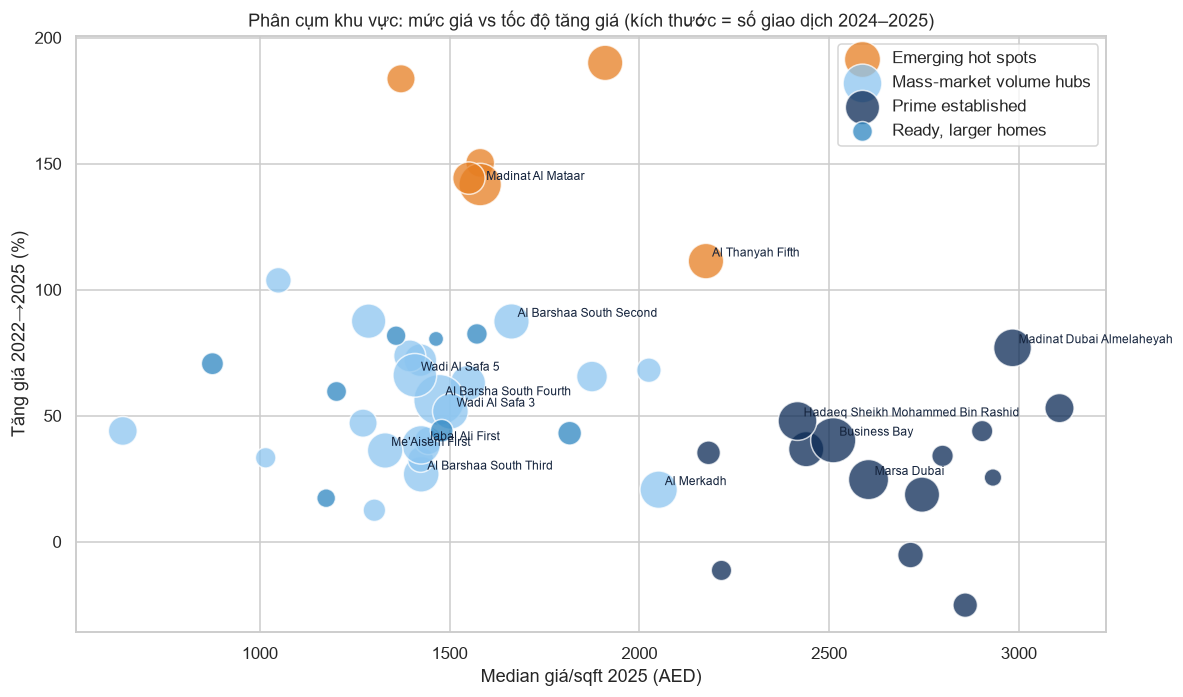

In [14]:
fig, ax = plt.subplots(figsize=(11, 6.5))
palette = {"Prime established": "#0B2A55", "Mass-market volume hubs": "#8CC5F0",
           "Ready, larger homes": "#2E86C1", "Emerging hot spots": "#E67E22"}
for name, part in areas.groupby("cluster_name"):
    ax.scatter(part["psf_2025"], part["growth_22_25"] * 100, s=np.sqrt(part["transactions_24_25"]) * 6,
               alpha=0.75, label=name, color=palette[name], edgecolor="white")
for area, row in areas.sort_values("transactions_24_25", ascending=False).head(14).iterrows():
    ax.annotate(area, (row["psf_2025"], row["growth_22_25"] * 100), fontsize=8,
                xytext=(4, 3), textcoords="offset points", color="#14233C")
ax.set(xlabel="Median giá/sqft 2025 (AED)", ylabel="Tăng giá 2022→2025 (%)",
       title="Phân cụm khu vực: mức giá vs tốc độ tăng giá (kích thước = số giao dịch 2024–2025)")
ax.legend(title="", loc="upper right")
plt.tight_layout(); plt.show()

In [15]:
for name, part in areas.sort_values("transactions_24_25", ascending=False).groupby("cluster_name"):
    print(f"{name:26s}: " + ", ".join(part.index[:6]))

Emerging hot spots        : Madinat Al Mataar, Al Thanyah Fifth, Al Hebiah First, Nadd Hessa, Al Hebiah Fifth, Wadi Al Safa 2
Mass-market volume hubs   : Al Barsha South Fourth, Wadi Al Safa 5, Jabal Ali First, Al Merkadh, Wadi Al Safa 3, Al Barshaa South Third
Prime established         : Business Bay, Marsa Dubai, Hadaeq Sheikh Mohammed Bin Rashid, Madinat Dubai Almelaheyah, Burj Khalifa, Al Khairan First
Ready, larger homes       : Al Thanyah Third, Al Hebiah Sixth, Jabal Ali, Al Thanayah Fourth, Al Yelayiss 1, Wadi Al Safa 6


## 2.4 Lưu kết quả phân cụm
Ghi bảng `area_cluster` vào MySQL (và file CSV) để Power BI có thể nối với `dim_area` qua `area_id` và tô màu biểu đồ theo cụm.

In [16]:
id_map = df.drop_duplicates("area_name_en").set_index("area_name_en")["area_id"]
out = areas.reset_index(names="area_name_en")
out.insert(0, "area_id", out["area_name_en"].map(id_map).astype(int))
out.to_sql("area_cluster", engine, if_exists="replace", index=False)
out.to_csv("data/processed/area_cluster.csv", index=False)
print(f"Đã lưu {len(out)} khu vực vào MySQL dld.area_cluster và data/processed/area_cluster.csv")
out.head()

Đã lưu 49 khu vực vào MySQL dld.area_cluster và data/processed/area_cluster.csv


,area_id,area_name_en,psf_2025,growth_22_25,transactions_24_25,offplan_share,median_size,cluster,cluster_name
0,442,Al Barsha South Fifth,"1,548.39",0.63,"7,959.00",0.84,65.01,1,Mass-market volume hubs
1,441,Al Barsha South Fourth,"1,472.72",0.56,"34,199.00",0.67,69.58,1,Mass-market volume hubs
2,414,Al Barshaa South Second,"1,663.14",0.87,"8,041.00",0.93,65.05,1,Mass-market volume hubs
3,409,Al Barshaa South Third,"1,425.19",0.27,"8,364.00",0.69,68.12,1,Mass-market volume hubs
4,451,Al Hebiah Fifth,"1,580.72",1.50,"3,523.00",0.77,71.62,0,Emerging hot spots


---
# Kết luận và đề xuất

### Mô hình định giá
- **LightGBM tốt nhất:** trên dữ liệu năm 2025 (mô hình chưa từng thấy), R² = **0,64** trên log giá. Sai số trung vị **13,4%** (MAE khoảng 317 AED/sqft), và **37%** giao dịch được dự đoán chính xác trong khoảng ±10%. Mô hình vượt rõ mốc Naive (sai số trung vị 25%) và Ridge (15,1%), chứng tỏ quan hệ giữa các biến và giá là phi tuyến.
- **Vị trí là yếu tố quyết định:** khu vực và master project chiếm khoảng **65%** mức quan trọng, xu hướng thị trường 17%, diện tích 9%, Off-Plan/Ready 5%. Số phòng và chỗ đậu xe gần như không thêm thông tin khi đã biết vị trí và diện tích.
- **Mô hình cũ đi nhanh:** sai số trên dữ liệu 2026 tăng lên **16,6%**. Cần huấn luyện lại định kỳ, ví dụ mỗi quý.
- **Nhiều biến hơn chưa chắc tốt hơn:** thêm tên dự án và tòa nhà làm mô hình kém đi (R² giảm từ 0,64 xuống 0,55), vì **43%** giao dịch năm 2025 thuộc dự án mới chưa có trong dữ liệu huấn luyện (vấn đề *cold start*).
- **Hạn chế:** dữ liệu không có view, tầng, chất lượng hoàn thiện hay thương hiệu chủ đầu tư. Hai khu Trade Center giao dịch cao hơn giá mô hình 170–190%, tức phân khúc siêu sang có thương hiệu nằm ngoài khả năng giải thích của mô hình. Không nên dùng mô hình để định giá phân khúc này.

### Phân cụm khu vực (k = 4, 49 khu vực)
| Cụm | Số khu | Median giá/sqft 2025 | Tăng giá 2022→2025 | Đặc điểm | Ví dụ |
|---|---|---|---|---|---|
| **Prime established** | 14 | ~2.730 AED | +35% | Giá cao nhất, tăng chậm nhất; vài khu đi ngang hoặc giảm | Business Bay, Marsa Dubai |
| **Emerging hot spots** | 6 | ~1.580 AED | **+147%** | Giá trung bình, tăng nhanh nhất, 71% là Off-Plan | Madinat Al Mataar, Al Hebiah |
| **Mass-market volume hubs** | 21 | ~1.420 AED | +52% | Nhiều giao dịch nhất, căn nhỏ (khoảng 69 m²) | Al Barsha South Fourth, Wadi Al Safa 5 |
| **Ready, larger homes** | 8 | ~1.410 AED | +65% | Chỉ 10% Off-Plan, căn lớn (khoảng 163 m²), khu villa đã hoàn thiện | Al Thanyah Third, Jabal Ali |

### Đề xuất kinh doanh
1. **Nhà đầu tư tìm tăng trưởng** nên chú ý nhóm *Emerging hot spots*: giá vào còn thấp hơn Prime khoảng 40% nhưng tăng giá gấp 4 lần. Rủi ro là nhóm này phụ thuộc Off-Plan, trong khi tổng số giao dịch năm 2026 đã giảm khoảng 21% so với cùng kỳ. Cần theo dõi tiến độ bàn giao.
2. **Mua để ở hoặc cho thuê, ưu tiên dễ bán lại**: nhóm *Mass-market volume hubs*, nơi có nhiều người mua nhất và mức giá vừa phải.
3. **Nhóm Prime** phù hợp để giữ tài sản hơn là lướt sóng: giá đã cao và tốc độ tăng đang chậm lại.
4. **Dùng mô hình định giá như công cụ kiểm tra giá chào bán:** nếu giá chào lệch hơn khoảng ±13% (sai số trung vị) so với giá mô hình thì cần xem xét kỹ. Mô hình cần huấn luyện lại mỗi quý và không áp dụng cho phân khúc siêu sang.